Fase 1: Limpieza del Log (Data Cleaning)
Al igual que en la vida real, los datos del servidor tienen errores. Utilicen pandas para limpiarlos:

- Eliminen cualquier fila donde el nombre del producto sea nulo.

- Estandaricen el formato (todo a MAYÚSCULAS) porque el sistema capturó "Laptop" y "laptop" como cosas distintas.

- El sistema falló algunas veces y guardó el ticket como "ERR_TIMEOUT". Eliminen esas transacciones.

- Regla de Negocio (Self-Loops): Si un cliente compró 2 "Teclados" en el mismo ticket por error (filas duplicadas en el mismo ID de Transacción), deben eliminar el duplicado. Para la red, solo nos importa qué productos distintos acompañan a otros, un producto no puede acompañarse a sí mismo.

In [8]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from google.colab import files

df = pd.read_csv('/content/compras_ecommerce.csv')

df = df.dropna(subset=['Producto'])
df['Producto'] = df['Producto'].str.upper()
df = df[df['ID_Transaccion'] != 'ERR_TIMEOUT']
df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto'])

display(df.head(50))

,ID_Transaccion,Producto
0,TKT-00181,TECLADO MECÁNICO RGB
1,TKT-01162,"MONITOR 27"" 144HZ"
2,TKT-00840,SILLA GAMER ERGONÓMICA
3,TKT-01734,SILLA GAMER ERGONÓMICA
4,TKT-01899,MOUSEPAD XL
5,TKT-02238,SILLA GAMER ERGONÓMICA
6,TKT-01128,"MONITOR 27"" 144HZ"
7,TKT-00876,"MONITOR 27"" 144HZ"
8,TKT-00542,MOUSE INALÁMBRICO
9,TKT-01260,MOUSE INALÁMBRICO


# Fase 2: Extracción (Colapsar el Grafo Bipartito)
Tienen una tabla bipartita implícita (Tickets -> Productos). Deben colapsarla para conectar Producto -> Producto.

- Utilicen pd.merge() para unir su dataframe limpio consigo mismo utilizando ID_Transaccion como llave de cruce.

- Filtren la tabla resultante para eliminar las conexiones de un producto consigo mismo, y eviten aristas duplicadas (no queremos contar "Mouse-Laptop" y luego "Laptop-Mouse" por separado).

- Agrupen (groupby) el resultado para contar cuántas veces ocurrió cada par. Ese conteo será su columna Peso.

In [9]:
import pandas as pd

merged_df = pd.merge(df, df, on='ID_Transaccion',suffixes=('_A', '_B'))

edges_df = merged_df[merged_df['Producto_A'] < merged_df['Producto_B']]

grafo_df = (
    edges_df.groupby(['Producto_A', 'Producto_B'])
    .size()
    .reset_index(name='Peso')
)

display(grafo_df.sort_values('Peso', ascending=False))

,Producto_A,Producto_B,Peso
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
38,MOUSE INALÁMBRICO,WEBCAM 1080P,361
40,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
31,"MONITOR 27"" 144HZ",MOUSEPAD XL,358
23,LAPTOP PRO 15,WEBCAM 1080P,351
42,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB,351
33,"MONITOR 27"" 144HZ",TECLADO MECÁNICO RGB,350
19,LAPTOP PRO 15,MOUSE INALÁMBRICO,347
39,MOUSEPAD XL,SILLA GAMER ERGONÓMICA,346
1,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341


Fase 3: Respuestas de Negocio (El Veredicto)
Pasen su tabla extraída a networkx (nx.from_pandas_edgelist) y respondan mediante código a su director de ventas:

- La Joya de la Corona: Usando la métrica de Degree Centrality (nx.degree_centrality), ¿Cuál es el "Producto Ancla" o "Hub" de su tienda? (Este es el producto que deben poner en la portada de la página web porque es el que más incita a comprar otras cosas).

- El Algoritmo en Acción: Revisen los pesos de sus aristas (o el diccionario de vecinos del grafo). Si un cliente acaba de meter un "TECLADO MECÁNICO RGB" a su carrito, ¿cuál es el producto exacto que el sistema debe recomendarle automáticamente para maximizar la probabilidad de venta conjunta?

- Renderizado: Dibujen el grafo, haciendo que el grosor de las líneas (width) sea proporcional al Peso de la conexión. Visualmente comprobarán su algoritmo.

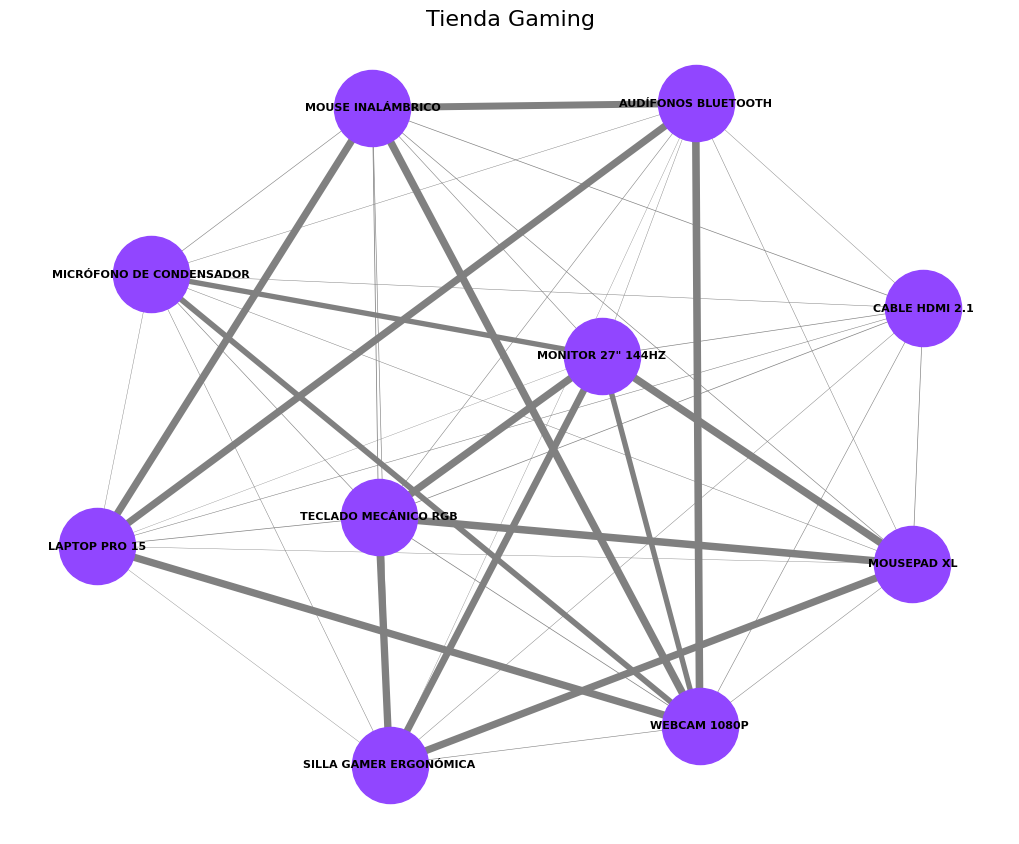

In [10]:
G_tienda = nx.from_pandas_edgelist(grafo_df, source='Producto_A', target='Producto_B', edge_attr='Peso', create_using=nx.Graph())

plt.figure(figsize=(10, 8))

pos = nx.spring_layout(G_tienda, seed=42)

pesos = [ d['Peso'] * 0.015 for (u, v, d) in G_tienda.edges(data=True)]

nx.draw(G_tienda, pos, with_labels=True, node_color='#9146FF', node_size=3000, font_color='black', font_weight='bold',
    font_size=8, width=pesos, edge_color='gray')

plt.title('Tienda Gaming', fontsize=16)
plt.show()

In [11]:
degree = nx.degree_centrality(G_tienda)

sorted_dict = dict(sorted(degree.items(), key=lambda item: item[1], reverse=True))
print(sorted_dict)



{'AUDÍFONOS BLUETOOTH': 1.0, 'CABLE HDMI 2.1': 1.0, 'LAPTOP PRO 15': 1.0, 'MICRÓFONO DE CONDENSADOR': 1.0, 'MONITOR 27" 144HZ': 1.0, 'MOUSE INALÁMBRICO': 1.0, 'MOUSEPAD XL': 1.0, 'SILLA GAMER ERGONÓMICA': 1.0, 'TECLADO MECÁNICO RGB': 1.0, 'WEBCAM 1080P': 1.0}


Preguntas

1. ¿Cuál es el "Producto Ancla" o "Hub" de su tienda?
R: no es posible identificar un único producto ancla utilizando esta métrica, ya que todos presentan el mismo número de conexiones de acuerdo a los resultados de degree centrality.

2. ¿Cuál es el producto exacto que el sistema debe recomendarle automáticamente para maximizar la probabilidad de venta conjunta?
R: El sistema debe recomendar el mousepad xl cuando un cliente agregue un Teclado mecánico RGB a su carrito.
